# Análisis exploratorio · The Spanish Fake News Corpus

Notebook de la Parte 2 (Jairo). Responde lo que pide la sección 5.1 del enunciado y la spec 10: distribución de clases, longitud de los textos, palabras más frecuentes y valores faltantes, más dos cosas propias de este corpus: los temas y las fuentes.

Cada sección termina con una **conclusión** y, cuando corresponde, con la decisión que se tomó en `params.yaml`.

Se ejecuta desde la carpeta `notebooks/` con el entorno del proyecto activado.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # para importar src/ desde notebooks/

import matplotlib.pyplot as plt
import pandas as pd

from src.config import ETIQUETAS, PARAMS
from src.data.cargar import cargar_crudo, cargar_procesado

pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
COLORES = {"falsa": "#d1495b", "verdadera": "#2e86ab"}

crudo = cargar_crudo()          # los tres .xlsx tal como vienen (columnas ya en minúsculas)
df = cargar_procesado()         # data/processed/noticias.csv, contrato C2
print("crudo:", crudo.shape, "| procesado:", df.shape)

crudo: (1543, 8) | procesado: (1542, 5)


## 1. Registros antes y después de limpiar

In [2]:
resumen = pd.DataFrame({
    "noticias": [len(crudo), len(df)],
}, index=["crudo (3 archivos)", "procesado (noticias.csv)"])
resumen.loc["eliminadas"] = resumen.iloc[0] - resumen.iloc[1]
resumen

,noticias
crudo (3 archivos),1543
procesado (noticias.csv),1542
eliminadas,1


**Conclusión.** De 1.543 noticias se pierde **una sola**: un duplicado exacto. No hay textos vacíos. El corpus llega casi intacto al modelo.

## 2. Valores faltantes

In [3]:
faltantes = crudo.isna().sum().to_frame("faltantes")
faltantes["%"] = (faltantes["faltantes"] / len(crudo) * 100).round(1)
faltantes[faltantes["faltantes"] > 0]

,faltantes,%
source,7,0.5
headline,72,4.7
link,3,0.2


In [4]:
# ¿De qué versión son los titulares vacíos?
crudo.assign(sin_titular=crudo["headline"].isna()).groupby("anio")["sin_titular"].sum()

anio
2018     0
2021    72
Name: sin_titular, dtype: int64

**Conclusión.**

- `headline`: 72 titulares vacíos, **todos de la v2** (2020-21). Por eso `cargar.py` usa solo el cuerpo cuando falta el titular, en lugar de descartar la noticia.
- `source` (7) y `link` (3) faltan en pocas filas. Ninguna de las dos entra al modelo, así que no afectan.
- `text` y `category` (la etiqueta) no tienen faltantes.

## 3. Distribución de clases

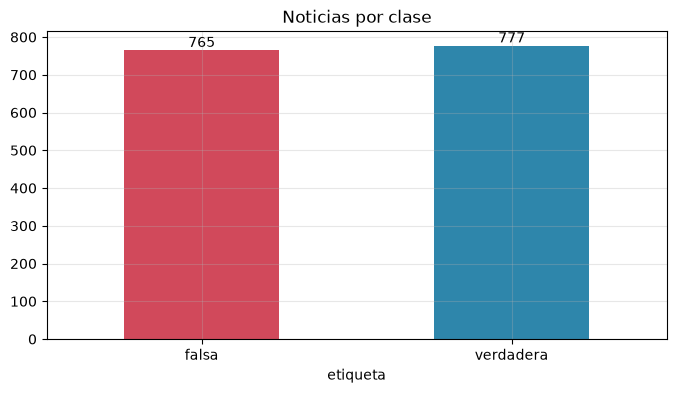

etiqueta
falsa        49.6
verdadera    50.4
Name: %, dtype: float64

In [5]:
conteo = df["etiqueta"].value_counts().reindex(ETIQUETAS)
ax = conteo.plot.bar(color=[COLORES[e] for e in conteo.index], rot=0)
ax.set_title("Noticias por clase")
ax.bar_label(ax.containers[0])
plt.show()
(conteo / len(df) * 100).round(1).rename("%")

In [6]:
# Por versión del corpus (v1 = 2018, v2 = 2020-21)
pd.crosstab(df["anio"], df["etiqueta"], margins=True)

etiqueta,falsa,verdadera,All
anio,,,
2018,479,491,970
2021,286,286,572
All,765,777,1542


**Conclusión.** 765 falsas (49,6 %) y 777 verdaderas (50,4 %): el corpus está **balanceado**, y también lo está cada versión por separado (479/491 y 286/286). Por eso:

- **No hace falta `class_weight`** ni sobremuestreo: las grillas de `params.yaml` ya no lo incluyen.
- La línea base (predecir siempre la clase mayoritaria) acierta solo la mitad: F1 macro ≈ 0,34. Cualquier modelo útil tiene que superarla con holgura.
- El split estratificado 80/20 mantiene esta proporción en train y test.

## 4. Longitud de los textos

In [7]:
df["palabras"] = df["texto"].str.split().str.len()
df["caracteres"] = df["texto"].str.len()

df.groupby("etiqueta")[["palabras", "caracteres"]].describe(percentiles=[0.01, 0.5, 0.95, 0.995]).T.round(0)

etiqueta            falsa  verdadera
palabras   count    765.0      777.0
           mean     347.0      537.0
           std      290.0      389.0
           min       28.0       51.0
           1%        54.0      115.0
           50%      283.0      436.0
           95%      671.0     1300.0
           99.5%   2146.0     2257.0
           max     4016.0     4017.0
caracteres count    765.0      777.0
           mean    2084.0     3284.0
           std     1774.0     2360.0
           min      173.0      326.0
           1%       339.0      683.0
           50%     1677.0     2613.0
           95%     4114.0     8000.0
           99.5%  12729.0    14138.0
           max    25872.0    24027.0

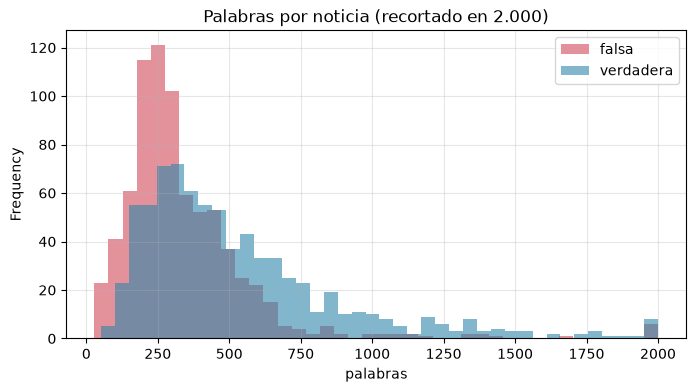

In [8]:
fig, ax = plt.subplots()
for etiqueta in ETIQUETAS:
    df.loc[df["etiqueta"] == etiqueta, "palabras"].clip(upper=2000).plot.hist(
        bins=40, alpha=0.6, ax=ax, label=etiqueta, color=COLORES[etiqueta])
ax.set_title("Palabras por noticia (recortado en 2.000)")
ax.set_xlabel("palabras")
ax.legend()
plt.show()

In [9]:
limites = PARAMS["api"]
print("noticia más corta:", df["palabras"].min(), "palabras")
print(f"noticias con menos de {limites['min_palabras']} palabras:", (df["palabras"] < limites["min_palabras"]).sum())
print("noticia más larga:", df["caracteres"].max(), "caracteres")
print(f"noticias con más de {limites['max_chars']} caracteres:", (df["caracteres"] > limites["max_chars"]).sum())

noticia más corta: 28 palabras
noticias con menos de 20 palabras: 0
noticia más larga: 25872 caracteres
noticias con más de 20000 caracteres: 2


**Conclusión.**

- Las **falsas son más cortas**: mediana de 283 palabras frente a 436 de las verdaderas. Las verdaderas tienen una cola larga (el 5 % supera las 1.300 palabras): son notas de agencia y reportajes. La longitud es una diferencia de **estilo**, no de veracidad. TF-IDF normaliza cada vector, así que el modelo no la usa directamente.
- **`min_palabras: 20`** (API): la noticia más corta del corpus tiene 28 palabras, así que el mínimo no rechaza ninguna noticia real y sí frena textos sin contenido suficiente para decidir.
- **`max_chars: 20000`** (API): solo 2 de 1.542 noticias lo superan (la más larga tiene 25.872 caracteres). Cubre el 99,9 % del corpus y evita textos desmedidos.

## 5. Palabras más frecuentes por clase

Se cuenta en **cuántas noticias** aparece cada palabra (frecuencia de documento), no cuántas veces: así una noticia larga no pesa más que una corta. Se usa el mismo `normalizar()` y `tokenizar()` del pipeline, sin lematizar, para leer palabras reales.

In [10]:
from collections import Counter

from src.nlp.normalizacion import normalizar, quitar_tildes
from src.nlp.stopwords import quitar_stopwords
from src.nlp.tokenizacion import tokenizar

tokens = df["texto"].map(lambda t: tokenizar(normalizar(t)))
con_stop = tokens.map(lambda ts: {quitar_tildes(t) for t in ts})
sin_stop = tokens.map(lambda ts: {quitar_tildes(t) for t in quitar_stopwords(ts)[0]})
n_clase = df["etiqueta"].value_counts()


def frecuencia_documento(conjuntos):
    """Proporción de noticias de cada clase que contienen cada palabra."""
    tabla = {}
    for etiqueta in ETIQUETAS:
        c = Counter(p for s in conjuntos[df["etiqueta"] == etiqueta] for p in s)
        tabla[etiqueta] = pd.Series(c) / n_clase[etiqueta]
    return pd.DataFrame(tabla).fillna(0)


fd_con = frecuencia_documento(con_stop)
fd_sin = frecuencia_documento(sin_stop)

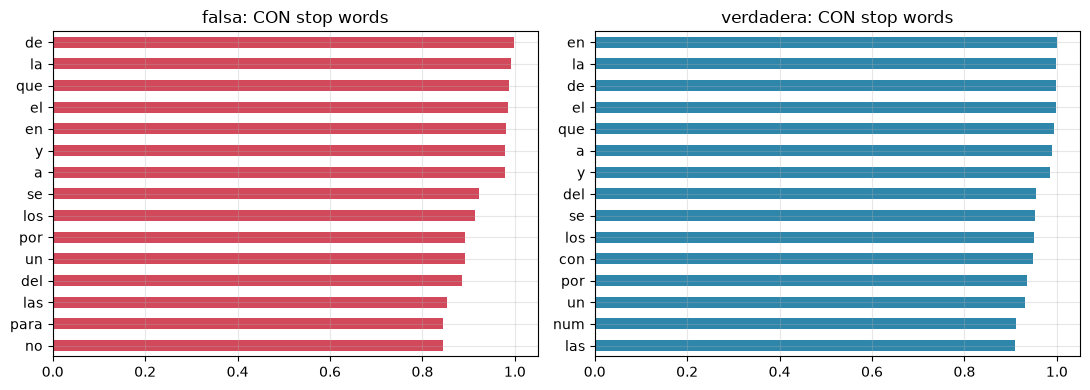

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, etiqueta in zip(ejes, ETIQUETAS):
    fd_con[etiqueta].nlargest(15).sort_values().plot.barh(ax=ax, color=COLORES[etiqueta])
    ax.set_title(f"{etiqueta}: CON stop words")
plt.tight_layout()
plt.show()

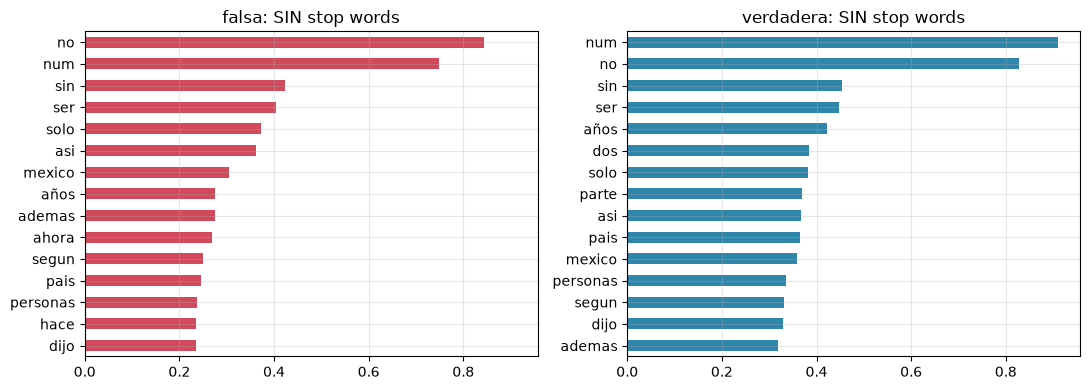

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, etiqueta in zip(ejes, ETIQUETAS):
    fd_sin[etiqueta].nlargest(15).sort_values().plot.barh(ax=ax, color=COLORES[etiqueta])
    ax.set_title(f"{etiqueta}: SIN stop words")
plt.tight_layout()
plt.show()

Las más frecuentes se parecen mucho entre clases. Lo que distingue es la **diferencia de proporción**: palabras frecuentes en una clase y raras en la otra (entre las que aparecen en al menos el 5 % de una clase).

In [13]:
fd = fd_sin[(fd_sin["falsa"] >= 0.05) | (fd_sin["verdadera"] >= 0.05)].copy()
fd["razon_falsa_verdadera"] = (fd["falsa"] + 0.01) / (fd["verdadera"] + 0.01)
print("Más asociadas a FALSAS")
display(fd.nlargest(12, "razon_falsa_verdadera").round(2))
print("Más asociadas a VERDADERAS")
display(fd.nsmallest(12, "razon_falsa_verdadera").round(2))

Más asociadas a FALSAS


,falsa,verdadera,razon_falsa_verdadera
puntualizo,0.09,0.01,5.13
menciono,0.08,0.03,2.03
darle,0.06,0.03,1.96
nadie,0.12,0.06,1.88
verdad,0.10,0.05,1.87
cosa,0.05,0.02,1.85
revelo,0.07,0.03,1.80
pueblo,0.06,0.03,1.74
exclamacion,0.15,0.09,1.67
conferencia,0.08,0.05,1.60


Más asociadas a VERDADERAS


,falsa,verdadera,razon_falsa_verdadera
destaco,0.01,0.07,0.21
juntos,0.01,0.07,0.26
febrero,0.02,0.09,0.30
sector,0.02,0.08,0.30
ocho,0.01,0.07,0.30
noviembre,0.02,0.09,0.31
indico,0.02,0.08,0.31
brasil,0.01,0.06,0.31
incluye,0.01,0.05,0.32
jueves,0.02,0.07,0.32


**Conclusión.**

- **Con stop words**, las 15 más frecuentes son artículos y preposiciones, iguales en las dos clases: no informan nada. Quitarlas (spec 20) es necesario.
- **Sin stop words**, las más frecuentes siguen siendo comunes a ambas clases: `no`, `num`, `sin`, `ser`, `solo`, `así`. `no` y `sin` aparecen porque se **conservan** a propósito (negaciones).
- Lo que separa las clases es el **estilo**:
  - Las **falsas** usan más verbos de declaración sensacionalistas («puntualizó», «reveló»), más apelaciones («verdad», «nadie», «pueblo», «medios») y más **exclamaciones**.
  - Las **verdaderas** usan el lenguaje de agencia: fechas («jueves», «febrero», «noviembre»), cifras escritas («ocho»), «instituto», «sector», «estatal», «destacó», «indicó».
- Esto confirma la limitación del informe: el modelo aprende **cómo está escrita** la noticia, no si lo que dice es cierto.

## 6. Temas por clase y por versión

La v1 etiqueta los temas en inglés (`Politics`, `Society`, `Science`, `Sport`) y la v2 en español (`Política`, `Sociedad`, `Ciencia`, `Deporte`). Para la EDA se unifican; el tema **no entra al modelo**.

In [14]:
TEMAS = {"Politics": "Política", "Society": "Sociedad", "Science": "Ciencia", "Sport": "Deporte",
         "Economy": "Economía", "Education": "Educación", "Entertainment": "Entretenimiento",
         "Health": "Salud", "Security": "Seguridad"}
df["tema_unificado"] = df["tema"].replace(TEMAS)

temas = pd.crosstab(df["tema_unificado"], df["etiqueta"])
temas["total"] = temas.sum(axis=1)
temas["% falsas"] = (temas["falsa"] / temas["total"] * 100).round(0)
temas.sort_values("total", ascending=False)

etiqueta,falsa,verdadera,total,% falsas
tema_unificado,,,,
Política,202,228,430,47.0
Sociedad,170,159,329,52.0
Covid-19,119,118,237,50.0
Entretenimiento,78,70,148,53.0
Deporte,58,67,125,46.0
Ciencia,50,52,102,49.0
Salud,23,23,46,50.0
Economía,19,24,43,44.0
Seguridad,25,17,42,60.0


In [15]:
pd.crosstab(df["tema_unificado"], df["anio"]).sort_values(2021, ascending=False).head(8)

anio,2018,2021
tema_unificado,,
Covid-19,0,237
Sociedad,134,195
Política,323,107
Internacional,0,14
Ciencia,89,13
Ambiental,0,4
Deporte,123,2
Economía,43,0


**Conclusión.**

- En **cada tema** hay casi tantas falsas como verdaderas (entre 40 % y 60 %): los autores armaron el corpus emparejando noticias por tema. Por eso el modelo **no puede acertar solo por el tema**: tiene que distinguir dentro de cada tema.
- La v2 (2020-21) está dominada por **COVID-19** (237 noticias), un tema que no existe en la v1. Si se entrena con 2018 y se prueba con 2020-21, el vocabulario cambia mucho: es el experimento opcional E3 de la spec 30.

## 7. Exclamaciones por clase

`normalizar()` convierte cada `!` o `¡` en el token `exclamacion` en lugar de borrarlo. ¿Tiene sentido?

In [16]:
df["exclamaciones"] = df["texto"].str.count(r"[!¡]")
df.groupby("etiqueta")["exclamaciones"].agg(
    media="mean",
    con_alguna=lambda s: f"{(s > 0).mean():.1%}",
).round(2)

,media,con_alguna
etiqueta,,
falsa,0.67,15.3%
verdadera,0.22,8.8%


**Conclusión.** El 15,3 % de las falsas tiene al menos una exclamación, frente al 8,8 % de las verdaderas, y en promedio usan **tres veces más** (0,67 frente a 0,22). Convertirlas en el token `exclamacion` conserva esa señal de tono sensacionalista. Borrarlas junto con la puntuación la perdería.

## 8. Fuentes: ¿quién publica cada clase?

In [17]:
fuentes = pd.crosstab(df["fuente"], df["etiqueta"])
fuentes["total"] = fuentes.sum(axis=1)

solo_falsas = fuentes[fuentes["verdadera"] == 0]
solo_verdaderas = fuentes[fuentes["falsa"] == 0]
mixtas = fuentes[(fuentes["falsa"] > 0) & (fuentes["verdadera"] > 0)]

pd.DataFrame({
    "fuentes": [len(solo_falsas), len(solo_verdaderas), len(mixtas)],
    "noticias falsas": [solo_falsas["falsa"].sum(), 0, mixtas["falsa"].sum()],
    "noticias verdaderas": [0, solo_verdaderas["verdadera"].sum(), mixtas["verdadera"].sum()],
}, index=["solo publican falsas", "solo publican verdaderas", "publican de las dos"])

,fuentes,noticias falsas,noticias verdaderas
solo publican falsas,188,735,0
solo publican verdaderas,145,0,605
publican de las dos,14,30,172


In [18]:
print("Fuentes que SOLO publican falsas (top 10)")
display(solo_falsas.nlargest(10, "total")[["falsa"]])
print("Fuentes que SOLO publican verdaderas (top 10)")
display(solo_verdaderas.nlargest(10, "total")[["verdadera"]])

Fuentes que SOLO publican falsas (top 10)


etiqueta,falsa
fuente,
El Dizque,143
El Ruinaversal,94
AFPFactual,90
Hay noticia,38
Censura 0,36
La voz popular,22
Retroceso,17
Mediterráneo Digital,16
Modo Noticia,15


Fuentes que SOLO publican verdaderas (top 10)


etiqueta,verdadera
fuente,
El país,68
Excelsior,52
Forbes,38
BBC News,28
EL UNIVERSAL,28
El Financiero,28
El País,28
Proceso,28
HUFFPOST,25


**Conclusión: la fuente casi decide la etiqueta.**

- De 347 fuentes, solo **14 publican de las dos clases**. El 96 % de las falsas (735 de 765) viene de fuentes que **nunca** publican una verdadera.
- Las más grandes son **sitios satíricos**: *El Dizque* (143) y *El Ruinaversal* (94) publican humor que imita noticias. *AFPFactual* (90) es un sitio de verificación: todo indica que los autores tomaron de ahí bulos ya desmentidos y registraron al verificador como fuente.
- Del otro lado están los medios y agencias: *El País*, *Excelsior*, *Forbes*, *BBC News*.

Por eso `cargar.py` guarda la columna `fuente` pero **no la usa como entrada del modelo**: con ella el modelo aprendería «si es de El Dizque, es falsa» y acertaría casi todo sin leer el texto. Ese resultado sería inútil con una noticia nueva de una fuente desconocida.

### 8.1 ¿La fuente se cuela dentro del texto?

Aunque la columna no entra, algunas noticias **firman** la agencia en el propio cuerpo («BBC News Mundo», «(AFP)», «Reuters»). Si esas firmas solo aparecen en una clase, el modelo puede usarlas como atajo.

In [19]:
FIRMAS = ["bbc", "afp", "efe", "reuters", "notimex"]
firmas = pd.DataFrame({
    f: df.assign(tiene=con_stop.map(lambda s, f=f: f in s)).groupby("etiqueta")["tiene"].sum()
    for f in FIRMAS
}).T
firmas

etiqueta,falsa,verdadera
bbc,0,26
afp,0,7
efe,2,7
reuters,0,8
notimex,0,3


**Conclusión.** Las firmas de agencia aparecen casi solo en las verdaderas: «bbc» en 26 verdaderas y 0 falsas, y lo mismo con «reuters» (8/0), «afp» (7/0) y «notimex» (3/0). «efe» sale en 7 verdaderas y 2 falsas. Son la **fuente filtrada dentro del texto**: dicen *quién* escribe, no *qué* dice la noticia. La sección 9 decide qué hacer con ellas.

## 9. Decisión: stop words del dominio (`params.yaml → nlp.agregar`)

Candidatas, según las secciones anteriores:

1. **Palabras comunes a ambas clases** («así», «solo», «ahora»). Brayan ya lo ensayó (receta B1): agregarlas **baja** el F1 de 0,786 a 0,776, porque en bigramas sí aportan. **Se descartan.**
2. **Firmas de agencia** (sección 8.1): no aportan contenido, solo la fuente.

Se mide el efecto de agregar las firmas con **validación cruzada de 5 particiones sobre el conjunto de entrenamiento**: el de prueba no se usa para decidir nada (spec 30). Tarda unos minutos porque lematiza las noticias en cada partición.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

from src.config import SEED
from src.models.train import construir_pipeline, dividir
from src.nlp import stopwords as sw

X_train, _, y_train, _ = dividir(cargar_procesado())
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
agregar_original = list(PARAMS["nlp"]["agregar"])

resultados = {}
for nombre, agregar in {"sin firmas (vacío)": [], "con firmas de agencia": FIRMAS}.items():
    PARAMS["nlp"]["agregar"] = agregar
    sw.obtener_stopwords.cache_clear()  # la lista de stop words se cachea: hay que recalcularla
    clf = LogisticRegression(max_iter=1000, random_state=SEED)
    f1 = cross_val_score(construir_pipeline(clf), X_train, y_train, cv=cv, scoring="f1_macro")
    resultados[nombre] = {"F1 macro (CV)": f1.mean().round(4), "desvío": f1.std().round(4)}

PARAMS["nlp"]["agregar"] = agregar_original
sw.obtener_stopwords.cache_clear()
pd.DataFrame(resultados).T

,F1 macro (CV),desvío
sin firmas (vacío),0.7631,0.0136
con firmas de agencia,0.7623,0.0130


**Decisión: `agregar: [bbc, afp, efe, reuters, notimex]`.**

- El F1 macro en validación cruzada **prácticamente no cambia**: la diferencia es mucho menor que el desvío entre particiones, así que es ruido.
- A igual rendimiento, se prefiere el modelo que **no depende de la firma de la agencia**: se le quita un atajo que no sirve con noticias sin firma, y las métricas reflejan mejor lo que el modelo aprende del contenido y el estilo.
- Las palabras comunes a ambas clases **no** se agregan (receta B1).

Es una línea en `params.yaml`; con eso la spec 10 queda cubierta y los experimentos de la 2.2 se hacen ya con esta lista.

## 10. Resumen de la EDA

| Pregunta | Respuesta | Decisión |
|---|---|---|
| ¿Cuántos datos se pierden al limpiar? | 1 duplicado de 1.543 | — |
| ¿Faltantes? | 72 titulares (v2), 7 fuentes, 3 enlaces | usar solo el cuerpo si falta el titular |
| ¿Clases balanceadas? | 765 / 777 (49,6 % / 50,4 %) | sin `class_weight`; split estratificado |
| ¿Longitudes? | falsas más cortas (283 vs 436 palabras de mediana) | `min_palabras: 20`, `max_chars: 20000` |
| ¿Palabras que distinguen? | estilo: sensacionalismo vs lenguaje de agencia | el modelo aprende estilo, no veracidad |
| ¿Temas? | balanceados dentro de cada tema; COVID solo en la v2 | E3 (opcional) mide el cambio temporal |
| ¿Exclamaciones? | 15 % de las falsas vs 9 % de las verdaderas | token `exclamacion` |
| ¿Fuentes? | el 96 % de las falsas viene de fuentes que solo publican falsas | `fuente` fuera del modelo |
| ¿Firmas en el texto? | «bbc», «afp», «reuters»… casi solo en verdaderas | `nlp.agregar` con las firmas |

# Parte 2 · Modelos, experimentos y errores

Esta parte lee `models/metricas.json`, que genera `python -m src.models.train` (PR 2.2). No reentrena: muestra y explica lo que salió del entrenamiento.

Regla para leer los números: **las decisiones se toman con el F1 macro de validación cruzada** (5 particiones, solo con train). El F1 de prueba se mira al final, una sola vez, para reportar.

In [21]:
import json

from src.config import RUTA_METRICAS

metricas = json.loads(RUTA_METRICAS.read_text(encoding="utf-8"))
print("Modelo en producción:", metricas["modelo_produccion"])
print("Criterio:", metricas["criterio"])
print(metricas["justificacion"])

Modelo en producción: regresion_logistica
Criterio: mayor F1 macro en validación cruzada (5 particiones, solo train)
Mayor F1 macro en validación cruzada: 0.766 ± 0.006 frente a naive bayes (0.695). En prueba obtiene 0.773, contra 0.336 de la línea base.


## 11. Comparación de modelos

La línea base predice siempre la clase mayoritaria. Los dos modelos se ajustaron con `GridSearchCV` sobre las grillas de `params.yaml → experiments.models`.

In [22]:
filas = {}
for nombre, m in metricas["modelos"].items():
    filas[nombre] = {
        "F1 CV (media)": m.get("f1_cv_media"), "F1 CV (desvío)": m.get("f1_cv_std"),
        "accuracy test": m["accuracy"], "precision test": m["precision_macro"],
        "recall test": m["recall_macro"], "F1 test": m["f1_macro"],
        "hiperparámetros": m.get("mejores_hiperparametros", "—"),
    }
comparacion = pd.DataFrame(filas).T
comparacion

,F1 CV (media),F1 CV (desvío),accuracy test,precision test,recall test,F1 test,hiperparámetros
baseline,None,None,0.5049,0.2524,0.5,0.3355,—
regresion_logistica,0.7663,0.0063,0.7735,0.7736,0.7733,0.7733,{'clf__C': 10.0}
naive_bayes,0.695,0.0236,0.7346,0.7438,0.7337,0.7316,{'clf__alpha': 0.1}


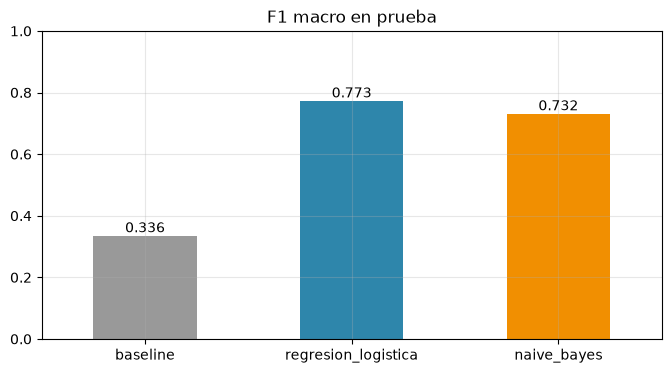

In [23]:
ax = comparacion["F1 test"].astype(float).plot.bar(rot=0, color=["#999999", "#2e86ab", "#f18f01"])
ax.bar_label(ax.containers[0], fmt="%.3f")
ax.set_ylim(0, 1)
ax.set_title("F1 macro en prueba")
plt.show()

**Conclusión.**

- Los dos modelos superan con holgura a la línea base (F1 ≈ 0,34): aprenden algo real del texto.
- **Regresión Logística gana en validación cruzada** y por eso va a producción. También gana en prueba, pero eso solo confirma: no participa en la decisión.
- Naive Bayes queda varios puntos atrás. Supone que las palabras son independientes entre sí dada la clase, y con TF-IDF de unigramas y bigramas esa suposición se rompe mucho: «no» y «no confirmar» están muy correlacionados. La Regresión Logística no hace esa suposición y reparte el peso entre términos correlacionados.
- El mejor `C` de la Regresión Logística es alto (poca regularización): con 20.000 términos y 1.233 noticias, el modelo necesita pesos grandes en pocos términos informativos.
- Naive Bayes prefiere un `alpha` bajo: menos suavizado, porque los términos raros pero muy asociados a una clase son justamente los informativos.

## 12. Matriz de confusión del modelo en producción

Filas = clase real, columnas = clase predicha.

In [24]:
prod = metricas["modelos"][metricas["modelo_produccion"]]
matriz = pd.DataFrame(prod["matriz_confusion"], index=[f"real {e}" for e in prod["etiquetas"]],
                      columns=[f"predicho {e}" for e in prod["etiquetas"]])
display(matriz)
pd.DataFrame(prod["por_clase"]).T

,predicho falsa,predicho verdadera
real falsa,116,37
real verdadera,33,123


,precision,recall,f1,soporte
falsa,0.7785,0.7582,0.7682,153.0
verdadera,0.7688,0.7885,0.7785,156.0


**Conclusión.** Los errores están repartidos entre las dos direcciones: hay falsas que pasan por verdaderas y verdaderas marcadas como falsas, en cantidades parecidas. El modelo no está sesgado hacia una clase, lo que es coherente con un corpus balanceado y sin `class_weight`. El error más costoso en la práctica es el de la primera fila: una falsa que se deja pasar como verdadera.

## 13. Experimentos E1 y E2: qué aporta cada decisión de NLP

Mismo modelo, mismos hiperparámetros; cambia **un solo** parámetro. F1 macro en validación cruzada.

In [25]:
exps = metricas["experimentos"]
e1 = pd.DataFrame(exps["stem_vs_lema"]).T
e2 = pd.DataFrame(exps["ngramas"]).T
print("E1 · stemming vs lematización"); display(e1)
print("E2 · unigramas vs unigramas + bigramas"); display(e2)

E1 · stemming vs lematización


,f1_macro,f1_std
stem,0.7658,0.0149
lema,0.7663,0.0063


E2 · unigramas vs unigramas + bigramas


,f1_macro,f1_std
"(1,1)",0.7602,0.0198
"(1,2)",0.7663,0.0063


**Conclusión.**

- **E1:** lematización y stemming quedan prácticamente empatados en F1. Se mantiene **lema** (`params.yaml → nlp.modo`) porque además tiene **menos variación entre particiones** (es más estable) y sus términos son palabras reales, lo que hace legibles las palabras influyentes y el paso a paso de la app. El costo es tiempo: lematizar con spaCy es más lento que el stemmer de Snowball.
- **E2:** sumar bigramas mejora el F1 (0,760 → 0,766) y además lo hace más estable (desvío 0,020 → 0,006). Los bigramas capturan lo que una palabra suelta pierde: entre los de más peso hacia «falsa» están «no creer», «no saber», «no querer» (negaciones, que se conservan a propósito como stop words), «fuente cercano» y «sin duda»; hacia «verdadera», «num mil», «año pasado» y «ciudad méxico». Se mantiene `ngram_range: [1, 2]`.

## 14. E3 · ¿Generaliza a otra época?

Entrenar con las noticias de 2018 (v1) y probar con las de 2020-21 (v2). No decide nada: mide un riesgo.

In [26]:
pd.DataFrame(exps["temporal"]).T

,accuracy,f1_macro,n_train,n_test
2018 -> 2020-21,0.6591,0.6431,970.0,572.0


**Conclusión.** El F1 cae de forma notable respecto del split mezclado. La EDA lo anticipaba: la v2 está dominada por COVID-19, un tema que no existe en 2018, y su vocabulario es otro. El modelo aprende **estilo y tema de una época**: para usarlo con noticias nuevas habría que reentrenarlo periódicamente. Es una limitación que va al informe.

## 15. Palabras más influyentes

Coeficientes de la Regresión Logística: cuánto empuja cada término (lematizado) hacia cada clase.

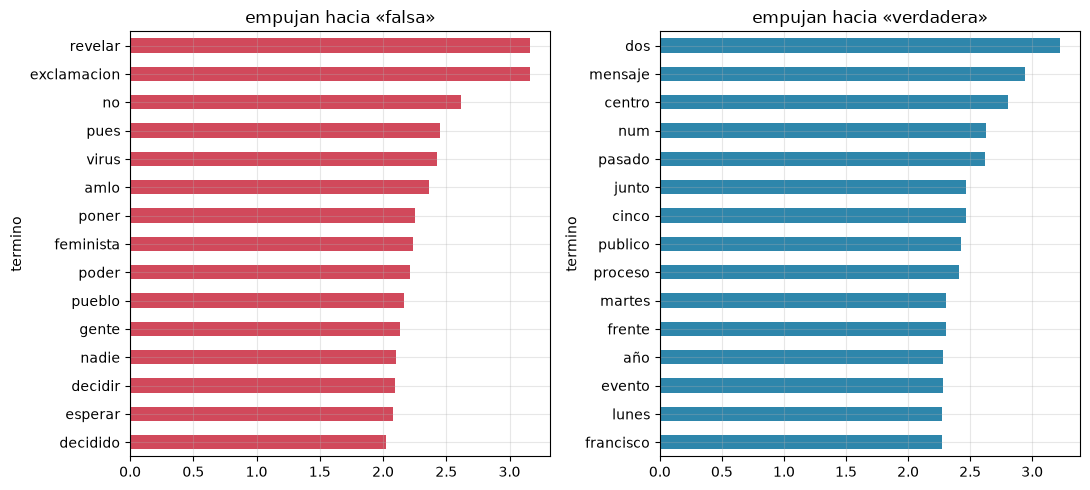

In [27]:
influyentes = metricas["palabras_influyentes"]
fig, ejes = plt.subplots(1, 2, figsize=(11, 5))
for ax, etiqueta in zip(ejes, ETIQUETAS):
    t = pd.DataFrame(influyentes[etiqueta]).set_index("termino")["peso"].abs().sort_values()
    t.plot.barh(ax=ax, color=COLORES[etiqueta])
    ax.set_title(f"empujan hacia «{etiqueta}»")
plt.tight_layout()
plt.show()

**Conclusión.** Confirma lo que mostró la EDA (sección 5):

- Hacia **«verdadera»** empujan las marcas del lenguaje de agencia: cifras («dos», «cinco», el token `num`), días y referencias temporales («lunes», «martes», «pasado», «año») y palabras de crónica («centro», «evento», «proceso»).
- Hacia **«falsa»** empujan el tono: «revelar», el token `exclamacion`, «pueblo», «gente», «nadie», «pues». También aparece «no»: las falsas niegan más («no hay», «nadie dice»).
- Hay además **palabras de tema** («virus», «amlo», «feminista») que pesan hacia «falsa» porque en este corpus abundan en bulos. Es un sesgo del corpus, no una regla general, y explica parte de los errores (sección 16).

El modelo decide sobre todo por **cómo está escrita** la noticia.

## 16. Análisis de errores

Los errores en que el modelo estaba **más seguro** (mayor probabilidad de la clase equivocada), en el conjunto de prueba.

In [28]:
errores = pd.DataFrame(metricas["errores_ejemplo"])
pd.set_option("display.max_colwidth", 160)
errores[["real", "predicho", "probabilidad", "tema", "fuente", "anio", "texto"]]

,real,predicho,probabilidad,tema,fuente,anio,texto
0,falsa,verdadera,0.9336,Covid-19,La comarca de Puerto Llano,2021,"Exvicepresidente de Pﬁzer: ""No hay necesidad de vacunas, la pandemia ha terminado"". Si bien la farmacéutica Pﬁzer llegó a los titulares al anunciar el lanza..."
1,falsa,verdadera,0.9032,Politics,Sin embargo,2018,"Forbes afirma que Angélica Rivera está ya en la lista de mexicanos millonarios en EU\nLa Primera Dama de México, Angélica Rivera Hurtado está en la lista de..."
2,falsa,verdadera,0.8825,Covid-19,AFPFactual,2021,Papelón: La diputada Ocasio-Cortez afirmó que su vida corrió peligro durante las protestas en el Capitolio pero se descubrió que ni siquiera estaba en el ed...
3,verdadera,falsa,0.8378,Sociedad,Milenio,2021,"Líder religioso que culpó a los homosexuales del coronavirus dio positivo al covid-19. El patriarca de la Iglesia ortodoxa de Ucrania, Patriarca Filaret (My..."
4,falsa,verdadera,0.8342,Sociedad,Gov,2021,Cali completó 48 horas con cero homicidios. “Ese es el mensaje que queremos darle al país y ojalá pudiéramos tener muchos días del año con cero homicidios p...
5,verdadera,falsa,0.8213,Sociedad,El Universal,2021,Feministas protestan frente a Palacio Nacional contra candidatura de Félix Salgado Macedonio. A unas horas que Félix Salgado Macedonio sea registrado como c...
6,falsa,verdadera,0.8195,Security,La otra opinion,2018,"Queman la sede del PRI municipal en Veracruz.\nA través de redes sociales, el presidente del Comité Municipal del Partido Revolucionario Institucional (PRI)..."
7,falsa,verdadera,0.8044,Sport,Hay noticia,2018,"Messi: ""Todavía estoy a tiempo de jugar con la selección española""\n En una entrevista aparecida hoy en el diario Sport de Barcelona, el astro argentino se ..."
8,verdadera,falsa,0.8030,Sport,Excelsior,2018,"Marchesín es intransferible, aclara el América\nSantiago Baños, presidente deportivo del equipo azulcrema, aseguró que no piensan prescindir de los servicio..."
9,falsa,verdadera,0.7739,Health,ABC sociedad,2018,"La Unión Europea podría prohibir los kebabs por sus riesgos para la salud\nEsta comida, originaria de Turquía, podría ser prohibida debido a sus vínculos co..."


### Cinco errores explicados

Los cinco son de la tabla anterior (de la fila 0 a la 9), elegidos porque muestran cinco causas distintas.

**1. Falsa con estilo de agencia y cita de autoridad** (fila 0, «Exvicepresidente de Pfizer: no hay necesidad de vacunas», 93 % verdadera).
Está escrita como una nota seria: titular con cita textual, un cargo («exvicepresidente y científico jefe»), sin exclamaciones ni apelaciones al lector. Son justo los rasgos que el modelo asocia con «verdadera». Lo falso es el **contenido**, y el modelo no verifica hechos: solo ve el estilo.

**2. Falsa que se apoya en un medio real** (fila 1, «Forbes afirma que Angélica Rivera está en la lista de millonarios», 90 % verdadera).
Atribuye la información a *Forbes* y a una columnista con nombre y apellido, y da detalles concretos (un condominio en Key Biscayne, un valor estimado). Citar fuentes y dar cifras es típico de las verdaderas. Un bulo que «toma prestada» la credibilidad de un medio conocido engaña al modelo igual que a un lector apurado.

**3. Verdadera con un tema que suena a bulo** (fila 3, «Líder religioso que culpó a los homosexuales del coronavirus dio positivo», 84 % falsa).
Es real (publicada por *Milenio*), pero tiene todo lo que en el corpus abunda entre las falsas: COVID-19, una figura polémica, ironía de la situación y «controversia en redes sociales». El modelo confunde **tema llamativo** con falsedad.

**4. Verdadera arrastrada por una palabra de tema** (fila 5, «Feministas protestan frente a Palacio Nacional», 82 % falsa).
«feminista» es uno de los términos con más peso hacia «falsa» (sección 15): en el entrenamiento aparece sobre todo en bulos políticos. Esta noticia de *El Universal* es real, pero ese término la empuja hacia la clase equivocada. Es un **sesgo de tema** aprendido de un corpus pequeño (1.233 noticias de entrenamiento).

**5. Sátira escrita como una entrevista** (fila 7, «Messi: todavía estoy a tiempo de jugar con la selección española», 80 % verdadera).
Viene de *Hay noticia*, un sitio que solo publica falsas, pero imita una entrevista deportiva con un medio real («el diario Sport de Barcelona»). Lo absurdo de la noticia es evidente para un lector que sabe de fútbol, pero no para un modelo de bolsa de palabras: no sabe quién es Messi ni qué es plausible.

**Patrón común.** El modelo acierta cuando el estilo delata a la noticia (exclamaciones, apelaciones, sensacionalismo) y falla cuando el estilo engaña: falsas bien redactadas y verdaderas sobre temas que suelen ser bulos. Es la limitación central del proyecto: **aprende cómo está escrita una noticia, no si es verdad**. Algunos errores, como la fila 4 (cifras oficiales de Cali etiquetadas como falsas), solo se podrían resolver contrastando el dato con otra fuente, algo que está fuera del alcance de un clasificador de texto.
